In [1]:
import os
from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
WANDB_ENTITY = "yrachynska-kyiv-school-of-economics"

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pytorch_lightning as pl
import torchmetrics
import wandb
import timm
import albumentations as A

from albumentations.pytorch import ToTensorV2
from pytorch_lightning.loggers import WandbLogger
from pytorch_lightning.callbacks import ModelCheckpoint, LearningRateMonitor
from PIL import Image
from sklearn.metrics import f1_score

In [2]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE)

cuda


# ResNet on Cats and Dogs++

## Data

In [3]:
CLASSES = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]
N_CLASSES = len(CLASSES)

DATA_DIR = '/kaggle/input/competitions/cats-and-dogs'

In [4]:
full_df = pd.read_csv("folds.csv")
full_df.head()

,image_id,Cat,Dog,Moris,Motya,Biatrix,cluster,fold
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0,0,3
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0,1,1
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0,2,0
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0,3,3
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0,4,1


In [5]:
class MultilabelImageDataset(torch.utils.data.Dataset):
    def __init__(self, df, img_dir, ext=".jpg", transform=None):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform
        self.ext = ext

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row["image_id"] + self.ext)
        image = np.array(Image.open(img_path).convert("RGB"))
        labels = torch.tensor(row[CLASSES].values.astype(np.float32))

        if self.transform:
            image = self.transform(image=image)["image"]

        return image, labels

## Augmentations

In [6]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_tfms = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.Affine(translate_percent=(-0.1, 0.1), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2()
])

val_tfms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2()
])

## Model and DataModule

In [7]:
class LitCNN(pl.LightningModule):
    def __init__(self, pos_weight, T_max, lr=1e-4):
        super().__init__()
        self.model = timm.create_model("resnet152.a1_in1k", pretrained=True, num_classes=N_CLASSES)
        self.criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight))
        self.val_f1 = torchmetrics.F1Score(task="multilabel", num_labels=N_CLASSES, average="macro")
        self.lr = lr
        self.T_max = T_max

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.criterion(self(x), y)
        self.log("train_loss", loss, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        self.log("val_loss", self.criterion(logits, y), on_epoch=True, prog_bar=True)
        self.val_f1.update((torch.sigmoid(logits) > 0.5).int(), y.int())

    def on_validation_epoch_end(self):
        self.log("val_f1", self.val_f1.compute(), prog_bar=True)
        self.val_f1.reset()

    def predict_step(self, batch, batch_idx):
        x, _ = batch
        return torch.sigmoid(self(x))

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=self.lr)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.T_max, eta_min=1e-6)
        return [optimizer], [{"scheduler": scheduler, "interval": "step"}]

class KaggleDataModule(pl.LightningDataModule):
    def __init__(self, df, img_dir, fold=0, batch_size=32, num_workers=4):
        super().__init__()
        self.df = df
        self.img_dir = img_dir
        self.fold = fold
        self.batch_size = batch_size
        self.num_workers = num_workers

    def setup(self, stage=None):
        train_df = self.df[self.df["fold"] != self.fold].reset_index(drop=True)
        val_df = self.df[self.df["fold"] == self.fold].reset_index(drop=True)

        n_pos = train_df[CLASSES].sum()
        self.pos_weight = np.sqrt((len(train_df) - n_pos) / n_pos).tolist()

        self.train_ds = MultilabelImageDataset(train_df, self.img_dir, transform=train_tfms)
        self.val_ds = MultilabelImageDataset(val_df, self.img_dir, transform=val_tfms)

    def train_dataloader(self):
        return torch.utils.data.DataLoader(
            self.train_ds, batch_size=self.batch_size, shuffle=True,
            num_workers=self.num_workers, pin_memory=True
        )

    def val_dataloader(self):
        return torch.utils.data.DataLoader(
            self.val_ds, batch_size=self.batch_size, shuffle=False,
            num_workers=self.num_workers, pin_memory=True
        )

## Training

In [8]:
N_EPOCHS = 15

datamodule = KaggleDataModule(df=full_df, img_dir=f"{DATA_DIR}/train/", fold=0)
datamodule.setup()
lit_model = LitCNN(
    pos_weight=datamodule.pos_weight,
    T_max=N_EPOCHS * len(datamodule.train_dataloader()),
)
wandb_logger = WandbLogger(
    entity=WANDB_ENTITY,
    project="cats-and-dogs", 
    name="resnet152"
)
checkpoint_cb = ModelCheckpoint(
    monitor="val_f1", mode="max",
    save_top_k=1, filename="resnet152-{epoch:02d}-{val_f1:.4f}"
)
lr_monitor = LearningRateMonitor(logging_interval="step")
trainer = pl.Trainer(
    max_epochs=N_EPOCHS,
    logger=wandb_logger,
    callbacks=[checkpoint_cb, lr_monitor],
    accelerator="auto",
    devices=1 if DEVICE == "cuda" else None,
    precision="16-mixed"
)

trainer.fit(lit_model, datamodule=datamodule)
wandb.finish()

model.safetensors: reconstructing file:   0%|          |  0.00B /  241MB            

model.safetensors: downloading bytes:           |  0.00B            

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: yrachynska (kaggle-casmi) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ ResNet            │ 58.2 M │ train │     0 │
│ 1 │ criterion │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 2 │ val_f1    │ MultilabelF1Score │      0 │ train │     0 │
└───┴───────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 58.2 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 58.2 M                                                                                               
Total estimated model params size (MB): 232.616                                                                    
Modules in train mode: 627                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_epochs=15` reached.


epoch,▁▁▁▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▅▆▆▇▇▇▇▇▇▇▇▇▇████
lr-Adam,███████▇▇▇▇▇▆▆▆▆▆▆▅▅▄▄▄▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁
train_loss_epoch,█▃▂▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_step,█▁▁▁▁▁▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
trainer/global_step,▁▁▁▁▁▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▇▇▇▇▇▇▇███
val_f1,▁▇▇▆▇▇▇████████
val_loss,█▄▂▂▁▁▁▁▁▁▁▁▁▁▁
epoch,14
lr-Adam,0.0
train_loss_epoch,0.0026
train_loss_step,0.00025


## Validation results and thresholds

In [12]:
val_df = datamodule.val_ds.df
val_targets = val_df[CLASSES].values
val_probs = torch.cat(trainer.predict(lit_model, datamodule.val_dataloader(), ckpt_path="best")).float().numpy()

print("Macro F1 (threshold 0.5):", round(f1_score(val_targets, val_probs > 0.5, average="macro"), 4))

def best_threshold(y, p):
    ts = np.linspace(0.05, 0.95, 91)
    f = [f1_score(y, p >= t, zero_division=0) for t in ts]
    return ts[int(np.argmax(f))], max(f)

thresholds = []
for k, cls in enumerate(CLASSES):
    t, f1_val = best_threshold(val_targets[:, k], val_probs[:, k])
    thresholds.append(t)
    print(f"{cls}: threshold={t:.2f}, F1={f1_val:.4f}")
thresholds = np.array(thresholds)

moris, motya = CLASSES.index("Moris"), CLASSES.index("Motya")

def keep_one(probs, thresholds):
    preds = (probs >= thresholds).astype(int)
    both = (preds[:, moris] == 1) & (preds[:, motya] == 1)
    unsure = (probs[:, moris] < 0.9) | (probs[:, motya] < 0.9)
    moris_wins = probs[:, moris] >= probs[:, motya]
    preds[both & unsure & moris_wins, motya] = 0
    preds[both & unsure & ~moris_wins, moris] = 0
    return preds

val_preds = keep_one(val_probs, thresholds)
print("Macro F1 (tuned thresholds):", round(f1_score(val_targets, val_probs >= thresholds, average="macro"), 4))
print("Macro F1 (+ keep_one):      ", round(f1_score(val_targets, val_preds, average="macro"), 4))

Restoring states from the checkpoint path at ./cats-and-dogs/lwvzmrcp/checkpoints/resnet152-epoch=11-val_f1=0.9410.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Loaded model weights from the checkpoint at ./cats-and-dogs/lwvzmrcp/checkpoints/resnet152-epoch=11-val_f1=0.9410.ckpt
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

Macro F1 (threshold 0.5): 0.941
Cat: threshold=0.14, F1=0.9965
Dog: threshold=0.60, F1=0.9980
Moris: threshold=0.54, F1=0.9286
Motya: threshold=0.81, F1=1.0000
Biatrix: threshold=0.46, F1=0.9412
Macro F1 (tuned thresholds): 0.9728
Macro F1 (+ keep_one):       0.9728


## Wrong predictions

wrong images: 12 of 2448
Cat: false positives 1, false negatives 6
Dog: false positives 4, false negatives 0
Moris: false positives 1, false negatives 1
Motya: false positives 0, false negatives 0
Biatrix: false positives 0, false negatives 1
image ids of the wrong images:
    "e45fd43462374234a2f09e2222efcd1edc4d122b",  # true: Cat | pred: Cat(1.00), Moris(0.96)
    "cf21db151627c203876b37312be72bc382fade84",  # true: Dog, Biatrix | pred: Dog(0.96)
    "77b1acacf40360eb46c9c9657f0d688312c80fa2",  # true: Cat, Dog, Moris, Biatrix | pred: Dog(1.00), Biatrix(1.00)
    "b7eb474277f3174f0e3abda8d4d801888ccaac04",  # true: Cat | pred: none
    "c46556f8273778f04fbeb6ab9ee33f3ec153390f",  # true: Cat | pred: none
    "cd0a07e5a4f4572508383d591d78d4da2cdf3a57",  # true: Cat | pred: none
    "521aed0b724bd93db1677b22d7321b5f208c61cf",  # true: Cat | pred: Dog(0.91)
    "587bca42a44c89d832b07b5e7f579ab24f07d60d",  # true: Cat | pred: Cat(0.19), Dog(0.95)
    "f8ae4f72f36c9f294a6bdc4a81805a8f863

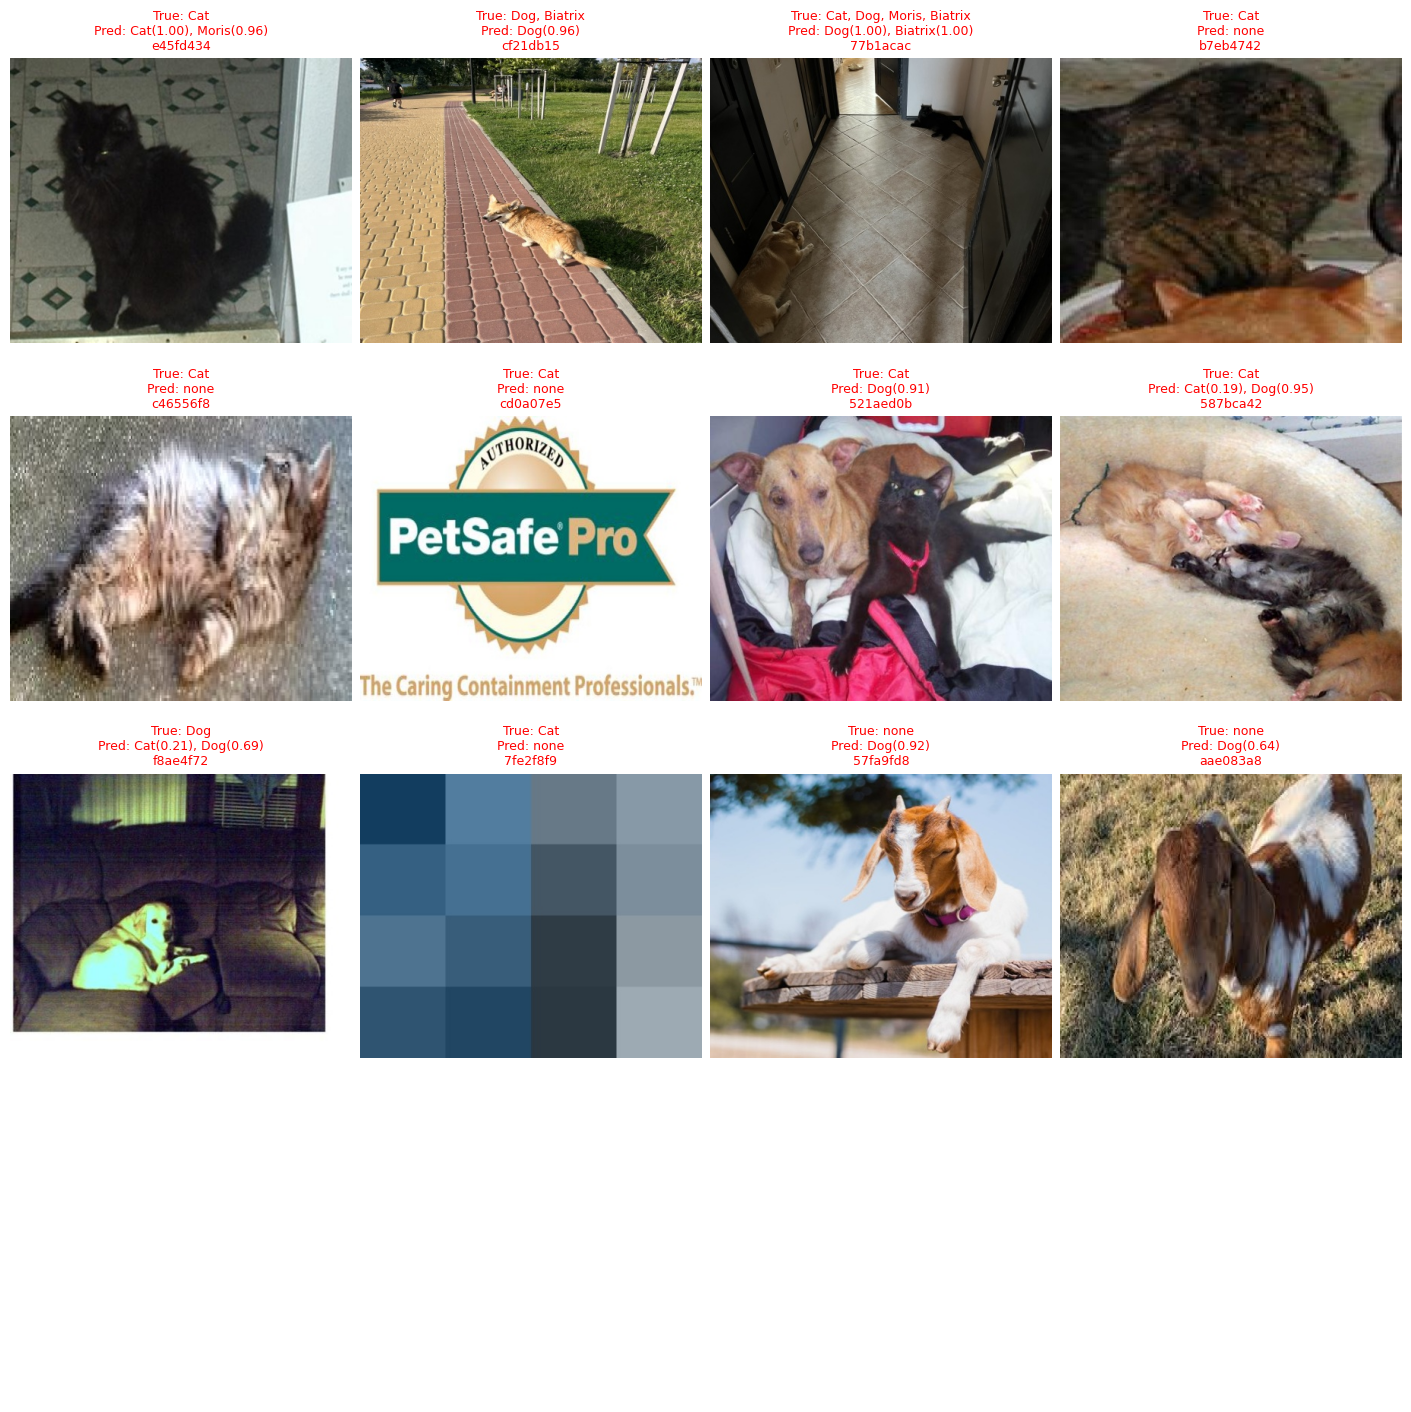

In [13]:
wrong = np.where((val_preds != val_targets).any(axis=1))[0]
print("wrong images:", len(wrong), "of", len(val_targets))

for k, cls in enumerate(CLASSES):
    fp = int(((val_preds[:, k] == 1) & (val_targets[:, k] == 0)).sum())
    fn = int(((val_preds[:, k] == 0) & (val_targets[:, k] == 1)).sum())
    print(f"{cls}: false positives {fp}, false negatives {fn}")

pet_idx = list(range(2, N_CLASSES))
pet_errors = (val_preds[:, pet_idx] != val_targets[:, pet_idx]).sum(axis=1)
order_all = wrong[np.argsort(-pet_errors[wrong], kind="stable")]

def describe(i):
    true_classes = [cls for k, cls in enumerate(CLASSES) if val_targets[i, k] == 1]
    pred_classes = [f"{cls}({val_probs[i, k]:.2f})" for k, cls in enumerate(CLASSES) if val_preds[i, k] == 1]
    return ", ".join(true_classes) or "none", ", ".join(pred_classes) or "none"

print("image ids of the wrong images:")
for i in order_all:
    true_str, pred_str = describe(i)
    print(f'    "{val_df.iloc[i].image_id}",  # true: {true_str} | pred: {pred_str}')

_, axes = plt.subplots(4, 4, figsize=(14, 14), layout="constrained")
for a in axes.ravel():
    a.axis("off")

for a, i in zip(axes.ravel(), order_all[:16]):
    row = val_df.iloc[i]
    a.imshow(Image.open(f"{DATA_DIR}/train/{row.image_id}.jpg"))
    true_str, pred_str = describe(i)
    a.set_title(f"True: {true_str}\nPred: {pred_str}\n{row.image_id[:8]}", fontsize=9, color="red")

plt.show()

In [14]:
test_df = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

test_ds = MultilabelImageDataset(test_df, f"{DATA_DIR}/test/", transform=val_tfms)
test_loader = torch.utils.data.DataLoader(
    test_ds, batch_size=32, shuffle=False, num_workers=4, pin_memory=True
)

test_probs = torch.cat(trainer.predict(lit_model, test_loader, ckpt_path="best")).float().numpy()

test_df[CLASSES] = keep_one(test_probs, thresholds)
test_df.to_csv("submission.csv", index=False)
test_df.head()

Restoring states from the checkpoint path at ./cats-and-dogs/lwvzmrcp/checkpoints/resnet152-epoch=11-val_f1=0.9410.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Loaded model weights from the checkpoint at ./cats-and-dogs/lwvzmrcp/checkpoints/resnet152-epoch=11-val_f1=0.9410.ckpt
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

,image_id,Cat,Dog,Moris,Motya,Biatrix
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24,0,0,0,0,0
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c,0,1,0,0,0
2,ac89f642faef21c92d622d882943e9065600354a,0,0,0,0,0
3,7245e7046ae54da95dbddc24ae814b3c61cc6237,1,0,0,0,0
4,d2b76179615de57b54cb00d094fba50810d96127,1,0,0,0,0
